# Part 4 — Mitigation: Making the Classifier Fairer and More Robust
**FAST-NUCES | Responsible & Explainable AI | Assignment 2**

Apply three bias mitigation techniques and measure their effect on both fairness metrics and overall accuracy.

- **Technique 1**: Reweighing (pre-processing) — aif360
- **Technique 2**: Threshold Optimization (post-processing) — fairlearn
- **Technique 3**: Oversampling (data augmentation)

All techniques are evaluated against the baseline from Part 1/2 on the same 20k eval set.

## 0. Imports

In [1]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score

from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric
from aif360.algorithms.preprocessing import Reweighing

from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import equalized_odds_difference, demographic_parity_difference

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE           = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME       = "distilbert-base-uncased"
BEST_MODEL_DIR   = "checkpoints/best_model"
MAX_LENGTH       = 128
CHOSEN_THRESHOLD = 0.4

print(f"Device : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[inFairness]'


Device : cuda
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load Artefacts from Parts 1 & 2

In [2]:
tokenizer   = AutoTokenizer.from_pretrained(BEST_MODEL_DIR)

df_eval     = pd.read_csv("checkpoints/eval_set.csv")
toxic_probs = np.load("checkpoints/toxic_probs.npy")
true_labels = np.load("checkpoints/true_labels.npy")

for col in ["black", "white", "muslim", "jewish", "homosexual_gay_or_lesbian"]:
    if col in df_eval.columns:
        df_eval[col] = df_eval[col].fillna(0.0)

df_eval["true_label"] = true_labels
df_eval["toxic_prob"] = toxic_probs
df_eval["pred_label"] = (toxic_probs >= CHOSEN_THRESHOLD).astype(int)

# Cohort masks (same thresholds as Part 2)
mask_black = df_eval["black"] >= 0.5
mask_ref   = (df_eval["black"] < 0.1) & (df_eval["white"] >= 0.5)

print(f"Eval set         : {len(df_eval):,} rows")
print(f"High-black cohort: {mask_black.sum()} rows")
print(f"Reference cohort : {mask_ref.sum()} rows")

Eval set         : 20,000 rows
High-black cohort: 164 rows
Reference cohort : 196 rows


In [3]:
# ── Reload training data (same split as Part 1) ───────────────────────────────
DATA_PATH = "data/jigsaw-unintended-bias-train.csv"

print("Loading CSV...")
df_full = pd.read_csv(
    DATA_PATH,
    usecols=["comment_text", "toxic", "black", "white",
             "muslim", "jewish", "homosexual_gay_or_lesbian"]
)
df_full["label"] = (df_full["toxic"] >= 0.5).astype(int)
df_full = df_full.dropna(subset=["comment_text"])

for col in ["black", "white"]:
    df_full[col] = df_full[col].fillna(0.0)

df_sample, _ = train_test_split(
    df_full, train_size=120_000, stratify=df_full["label"], random_state=SEED
)
df_train, _ = train_test_split(
    df_sample, test_size=20_000, stratify=df_sample["label"], random_state=SEED
)
df_train = df_train.reset_index(drop=True)

print(f"Training set size : {len(df_train):,}")

Loading CSV...
Training set size : 100,000


## Helper: Shared Utilities

In [4]:
class JigsawDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts, self.labels = texts, labels
        self.tokenizer, self.max_length = tokenizer, max_length

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]), max_length=self.max_length,
            truncation=True, padding="max_length", return_tensors="pt"
        )
        return {
            "input_ids":      enc["input_ids"].squeeze(),
            "attention_mask": enc["attention_mask"].squeeze(),
            "labels":         torch.tensor(self.labels[idx], dtype=torch.long)
        }


def get_training_args(output_dir):
    return TrainingArguments(
        output_dir=output_dir, num_train_epochs=3,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        learning_rate=2e-5, warmup_ratio=0.1, weight_decay=0.01,
        evaluation_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1_macro",
        logging_steps=200, seed=SEED, fp16=True, report_to="none"
    )


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro")
    }


def get_probs(trainer, dataset):
    """Run Trainer.predict and return softmax toxic-class probabilities."""
    output = trainer.predict(dataset)
    return torch.softmax(torch.tensor(output.predictions), dim=-1).numpy()[:, 1]


def cohort_fpr(df, pred_col="pred_label"):
    """FPR for a cohort dataframe."""
    non_toxic = df[df["true_label"] == 0]
    if len(non_toxic) == 0: return 0.0
    return (non_toxic[pred_col] == 1).mean()


def aif360_fairness(df, pred_col="pred_label"):
    """Return (SPD, EOD) using aif360 on the full eval set with group column."""
    df_u = df[mask_black][["true_label", pred_col]].copy()
    df_u["group"] = 0
    df_p = df[mask_ref][["true_label", pred_col]].copy()
    df_p["group"] = 1
    combined = pd.concat([df_u, df_p], ignore_index=True)

    ds_true = BinaryLabelDataset(
        df=combined[["true_label", "group"]].rename(columns={"true_label": "label"}),
        label_names=["label"], protected_attribute_names=["group"],
        favorable_label=0, unfavorable_label=1
    )
    ds_pred = BinaryLabelDataset(
        df=combined[[pred_col, "group"]].rename(columns={pred_col: "label"}),
        label_names=["label"], protected_attribute_names=["group"],
        favorable_label=0, unfavorable_label=1
    )
    m = ClassificationMetric(
        ds_true, ds_pred,
        unprivileged_groups=[{"group": 0}],
        privileged_groups=[{"group": 1}]
    )
    return m.statistical_parity_difference(), m.equal_opportunity_difference()


# ── Baseline metrics (from Part 1/2) ─────────────────────────────────────────
baseline_f1     = f1_score(true_labels, df_eval["pred_label"], average="macro")
baseline_fpr_b  = cohort_fpr(df_eval[mask_black])
baseline_fpr_r  = cohort_fpr(df_eval[mask_ref])
baseline_spd, baseline_eod = aif360_fairness(df_eval)

results_table = [{
    "Technique"       : "Baseline (Part 1)",
    "Overall F1"      : round(baseline_f1,    4),
    "High-black FPR"  : round(baseline_fpr_b, 4),
    "Reference FPR"   : round(baseline_fpr_r, 4),
    "Stat. Parity Δ"  : round(baseline_spd,   4),
    "Equal Opp. Δ"    : round(baseline_eod,   4),
}]

eval_dataset = JigsawDataset(
    df_eval["comment_text"].tolist(),
    df_eval["true_label"].tolist(),
    tokenizer, MAX_LENGTH
)

print("Baseline metrics computed.")
print(f"  F1 Macro       : {baseline_f1:.4f}")
print(f"  High-black FPR : {baseline_fpr_b:.4f}")
print(f"  Reference FPR  : {baseline_fpr_r:.4f}")
print(f"  Stat. Parity Δ : {baseline_spd:.4f}")
print(f"  Equal Opp. Δ   : {baseline_eod:.4f}")

Baseline metrics computed.
  F1 Macro       : 0.8114
  High-black FPR : 0.1345
  Reference FPR  : 0.1049
  Stat. Parity Δ : -0.0448
  Equal Opp. Δ   : -0.0296


# Technique 1 — Reweighing (Pre-processing)

aif360's `Reweighing` computes per-sample weights that correct for under/over-representation of subgroups in the training data. We then pass these weights into a custom `Trainer` that applies a weighted cross-entropy loss, so the model sees high-black examples as more important during training.

- **Privileged group**: reference cohort (white ≥ 0.5, black < 0.1)
- **Unprivileged group**: high-black cohort (black ≥ 0.5)
- All other rows: assigned to unprivileged group by default (conservative choice)

In [5]:
# ── Assign protected attribute to training rows ───────────────────────────────
df_train_rw = df_train.copy()
df_train_rw["group"] = np.where(df_train_rw["black"] >= 0.5, 0, 1)  # 0 = unprivileged

print(f"Unprivileged (black >= 0.5) in training : {(df_train_rw.group == 0).sum():,}")
print(f"Privileged   (others)      in training : {(df_train_rw.group == 1).sum():,}")

# ── Build aif360 BinaryLabelDataset for training data ────────────────────────
train_aif = BinaryLabelDataset(
    df=df_train_rw[["label", "group"]],
    label_names=["label"],
    protected_attribute_names=["group"],
    favorable_label=0,
    unfavorable_label=1
)

# ── Fit Reweighing and extract instance weights ───────────────────────────────
rw = Reweighing(
    unprivileged_groups=[{"group": 0}],
    privileged_groups=[{"group": 1}]
)
train_aif_rw = rw.fit_transform(train_aif)
sample_weights = train_aif_rw.instance_weights

print(f"\nSample weight stats:")
print(f"  Min    : {sample_weights.min():.4f}")
print(f"  Max    : {sample_weights.max():.4f}")
print(f"  Mean   : {sample_weights.mean():.4f}")
print(f"  Unprivileged mean weight : {sample_weights[df_train_rw.group == 0].mean():.4f}")
print(f"  Privileged   mean weight : {sample_weights[df_train_rw.group == 1].mean():.4f}")

Unprivileged (black >= 0.5) in training : 814
Privileged   (others)      in training : 99,186

Sample weight stats:
  Min    : 0.2402
  Max    : 1.3792
  Mean   : 1.0000
  Unprivileged mean weight : 1.0000
  Privileged   mean weight : 1.0000


In [9]:
# ── Weighted Dataset & Custom Trainer ────────────────────────────────────────
class WeightedJigsawDataset(Dataset):
    def __init__(self, texts, labels, weights, tokenizer, max_length):
        self.texts, self.labels = texts, labels
        self.weights = weights
        self.tokenizer, self.max_length = tokenizer, max_length

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]), max_length=self.max_length,
            truncation=True, padding="max_length", return_tensors="pt"
        )
        return {
            "input_ids":      enc["input_ids"].squeeze(),
            "attention_mask": enc["attention_mask"].squeeze(),
            "labels":         torch.tensor(self.labels[idx], dtype=torch.long)
        }


class WeightedTrainer(Trainer):
    """Trainer that applies per-sample weights to the cross-entropy loss."""
    def __init__(self, *args, sample_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.sample_weights = torch.tensor(sample_weights, dtype=torch.float32) if sample_weights is not None else None
        self.current_idx = 0
    
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        batch_size = inputs["input_ids"].shape[0]
        
        # Get weights for this batch from the stored sample_weights
        if self.sample_weights is not None:
            batch_indices = torch.arange(self.current_idx, self.current_idx + batch_size)
            weights = self.sample_weights[batch_indices].to(DEVICE)
            self.current_idx = (self.current_idx + batch_size) % len(self.sample_weights)
        else:
            weights = torch.ones(batch_size, dtype=torch.float32).to(DEVICE)
        
        labels  = inputs["labels"]
        outputs = model(**inputs)
        logits  = outputs.logits
        loss_fn = torch.nn.CrossEntropyLoss(reduction="none")
        loss    = loss_fn(logits, labels)
        weighted_loss = (loss * weights).mean()
        return (weighted_loss, outputs) if return_outputs else weighted_loss


weighted_train_dataset = WeightedJigsawDataset(
    df_train_rw["comment_text"].tolist(),
    df_train_rw["label"].tolist(),
    sample_weights.tolist(),
    tokenizer, MAX_LENGTH
)

model_rw = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model_rw.to(DEVICE)

trainer_rw = WeightedTrainer(
    model=model_rw,
    args=get_training_args("checkpoints/distilbert-reweighed"),
    train_dataset=weighted_train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
    sample_weights=sample_weights
)

print("Training reweighed model...")
trainer_rw.train()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training reweighed model...


  0%|          | 0/18750 [00:00<?, ?it/s]

{'loss': 0.5351, 'grad_norm': 1.8152638673782349, 'learning_rate': 2.133333333333334e-06, 'epoch': 0.03}
{'loss': 0.2822, 'grad_norm': 1.4634084701538086, 'learning_rate': 4.256e-06, 'epoch': 0.06}
{'loss': 0.1993, 'grad_norm': 2.88321590423584, 'learning_rate': 6.389333333333334e-06, 'epoch': 0.1}
{'loss': 0.2135, 'grad_norm': 0.3870602548122406, 'learning_rate': 8.522666666666667e-06, 'epoch': 0.13}
{'loss': 0.1825, 'grad_norm': 0.5332224369049072, 'learning_rate': 1.0645333333333335e-05, 'epoch': 0.16}
{'loss': 0.1781, 'grad_norm': 4.007137775421143, 'learning_rate': 1.2778666666666668e-05, 'epoch': 0.19}
{'loss': 0.184, 'grad_norm': 3.118105888366699, 'learning_rate': 1.4912000000000002e-05, 'epoch': 0.22}
{'loss': 0.1725, 'grad_norm': 0.7735846638679504, 'learning_rate': 1.7045333333333334e-05, 'epoch': 0.26}
{'loss': 0.1935, 'grad_norm': 4.348552703857422, 'learning_rate': 1.9178666666666666e-05, 'epoch': 0.29}
{'loss': 0.1658, 'grad_norm': 3.5653812885284424, 'learning_rate': 1.

  0%|          | 0/625 [00:00<?, ?it/s]

...

  0%|          | 0/625 [00:00<?, ?it/s]

{'eval_loss': 0.1693090945482254, 'eval_accuracy': 0.9489, 'eval_f1_macro': 0.8096564238852357, 'eval_runtime': 36.8886, 'eval_samples_per_second': 542.173, 'eval_steps_per_second': 16.943, 'epoch': 2.0}
{'loss': 0.0999, 'grad_norm': 1.0306326150894165, 'learning_rate': 7.296000000000001e-06, 'epoch': 2.02}
{'loss': 0.0804, 'grad_norm': 0.4933907687664032, 'learning_rate': 7.058962962962963e-06, 'epoch': 2.05}
{'loss': 0.0796, 'grad_norm': 7.0723114013671875, 'learning_rate': 6.821925925925926e-06, 'epoch': 2.08}
{'loss': 0.0781, 'grad_norm': 9.874129295349121, 'learning_rate': 6.586074074074075e-06, 'epoch': 2.11}
{'loss': 0.1016, 'grad_norm': 4.592731952667236, 'learning_rate': 6.349037037037038e-06, 'epoch': 2.14}
{'loss': 0.0884, 'grad_norm': 10.292497634887695, 'learning_rate': 6.112e-06, 'epoch': 2.18}
{'loss': 0.0822, 'grad_norm': 20.03441047668457, 'learning_rate': 5.8749629629629636e-06, 'epoch': 2.21}
{'loss': 0.0989, 'grad_norm': 0.18901847302913666, 'learning_rate': 5.63792

  0%|          | 0/625 [00:00<?, ?it/s]

{'eval_loss': 0.21546567976474762, 'eval_accuracy': 0.94675, 'eval_f1_macro': 0.8097962248729762, 'eval_runtime': 36.514, 'eval_samples_per_second': 547.735, 'eval_steps_per_second': 17.117, 'epoch': 3.0}
{'train_runtime': 2318.2488, 'train_samples_per_second': 129.408, 'train_steps_per_second': 8.088, 'train_loss': 0.1295396896870931, 'epoch': 3.0}


TrainOutput(global_step=18750, training_loss=0.1295396896870931, metrics={'train_runtime': 2318.2488, 'train_samples_per_second': 129.408, 'train_steps_per_second': 8.088, 'total_flos': 9935054899200000.0, 'train_loss': 0.1295396896870931, 'epoch': 3.0})

In [10]:
# ── Evaluate reweighed model ──────────────────────────────────────────────────
probs_rw = get_probs(trainer_rw, eval_dataset)
preds_rw = (probs_rw >= CHOSEN_THRESHOLD).astype(int)

df_eval["pred_rw"] = preds_rw

rw_f1    = f1_score(true_labels, preds_rw, average="macro")
rw_fpr_b = cohort_fpr(df_eval[mask_black], pred_col="pred_rw")
rw_fpr_r = cohort_fpr(df_eval[mask_ref],   pred_col="pred_rw")
rw_spd, rw_eod = aif360_fairness(df_eval, pred_col="pred_rw")

results_table.append({
    "Technique"       : "Reweighing (pre-proc)",
    "Overall F1"      : round(rw_f1,    4),
    "High-black FPR"  : round(rw_fpr_b, 4),
    "Reference FPR"   : round(rw_fpr_r, 4),
    "Stat. Parity Δ"  : round(rw_spd,   4),
    "Equal Opp. Δ"    : round(rw_eod,   4),
})

np.save("checkpoints/probs_reweighed.npy", probs_rw)
trainer_rw.save_model("checkpoints/best_model_rw")
tokenizer.save_pretrained("checkpoints/best_model_rw")

print(f"Reweighing results:")
print(f"  F1 Macro       : {rw_f1:.4f}  (baseline: {baseline_f1:.4f})")
print(f"  High-black FPR : {rw_fpr_b:.4f}  (baseline: {baseline_fpr_b:.4f})")
print(f"  Reference FPR  : {rw_fpr_r:.4f}  (baseline: {baseline_fpr_r:.4f})")
print(f"  Stat. Parity Δ : {rw_spd:.4f}  (baseline: {baseline_spd:.4f})")
print(f"  Equal Opp. Δ   : {rw_eod:.4f}  (baseline: {baseline_eod:.4f})")

  0%|          | 0/625 [00:00<?, ?it/s]

Reweighing results:
  F1 Macro       : 0.8090  (baseline: 0.8114)
  High-black FPR : 0.1345  (baseline: 0.1345)
  Reference FPR  : 0.0909  (baseline: 0.1049)
  Stat. Parity Δ : -0.0703  (baseline: -0.0448)
  Equal Opp. Δ   : -0.0435  (baseline: -0.0296)


# Technique 2 — Threshold Optimization (Post-processing)

Instead of retraining, we adjust the decision threshold **separately for each subgroup** to equalise a chosen fairness metric. We use fairlearn's `ThresholdOptimizer` with `equalized_odds` as the constraint.

We then plot the **accuracy-fairness Pareto frontier** by sweeping group-specific thresholds, showing the trade-off between F1 and equal opportunity difference.

In [18]:
from sklearn.base import BaseEstimator, ClassifierMixin

# ── Wrap DistilBERT as a sklearn-compatible estimator for fairlearn ────────────
class DistilBertSklearnWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self):
        self.classes_ = np.array([0, 1])

    def fit(self, X, y, **kwargs):
        return self

    def predict_proba(self, X):
        # X contains the toxic probabilities directly — no index tracking needed
        p = np.array(X).flatten()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= CHOSEN_THRESHOLD).astype(int)


# ── Build arrays for the combined (black + ref) cohort only ──────────────────
# ThresholdOptimizer needs sensitive_features aligned with X
idx_b   = df_eval[mask_black].index.tolist()
idx_r   = df_eval[mask_ref].index.tolist()
idx_all = idx_b + idx_r

y_cohort      = df_eval.loc[idx_all, "true_label"].values
probs_cohort  = toxic_probs[idx_all]
groups_cohort = np.array([0] * len(idx_b) + [1] * len(idx_r))  # 0=black, 1=ref

print(f"Combined cohort size : {len(idx_all)} (black={len(idx_b)}, ref={len(idx_r)})")

Combined cohort size : 360 (black=164, ref=196)


In [19]:
# Dummy X (ThresholdOptimizer only uses predict_proba, not raw features)
X_probs = probs_cohort.reshape(-1, 1)

wrapper = DistilBertSklearnWrapper()

to = ThresholdOptimizer(
    estimator=wrapper,
    constraints="equalized_odds",
    objective="balanced_accuracy_score",
    predict_method="predict_proba"
)

to.fit(X_probs, y_cohort, sensitive_features=groups_cohort)
preds_to_cohort = to.predict(X_probs, sensitive_features=groups_cohort)

# Map optimised predictions back into the full eval dataframe
df_eval["pred_to"] = df_eval["pred_label"].copy()  # default: keep baseline prediction
df_eval.loc[idx_all, "pred_to"] = preds_to_cohort

to_f1    = f1_score(true_labels, df_eval["pred_to"], average="macro")
to_fpr_b = cohort_fpr(df_eval[mask_black], pred_col="pred_to")
to_fpr_r = cohort_fpr(df_eval[mask_ref],   pred_col="pred_to")
to_spd, to_eod = aif360_fairness(df_eval, pred_col="pred_to")

results_table.append({
    "Technique"       : "ThresholdOptimizer (post)",
    "Overall F1"      : round(to_f1,    4),
    "High-black FPR"  : round(to_fpr_b, 4),
    "Reference FPR"   : round(to_fpr_r, 4),
    "Stat. Parity Δ"  : round(to_spd,   4),
    "Equal Opp. Δ"    : round(to_eod,   4),
})

print(f"ThresholdOptimizer results:")
print(f"  F1 Macro       : {to_f1:.4f}")
print(f"  High-black FPR : {to_fpr_b:.4f}")
print(f"  Reference FPR  : {to_fpr_r:.4f}")
print(f"  Stat. Parity Δ : {to_spd:.4f}")
print(f"  Equal Opp. Δ   : {to_eod:.4f}")

ThresholdOptimizer results:
  F1 Macro       : 0.8120
  High-black FPR : 0.1261
  Reference FPR  : 0.1189
  Stat. Parity Δ : -0.0132
  Equal Opp. Δ   : -0.0072


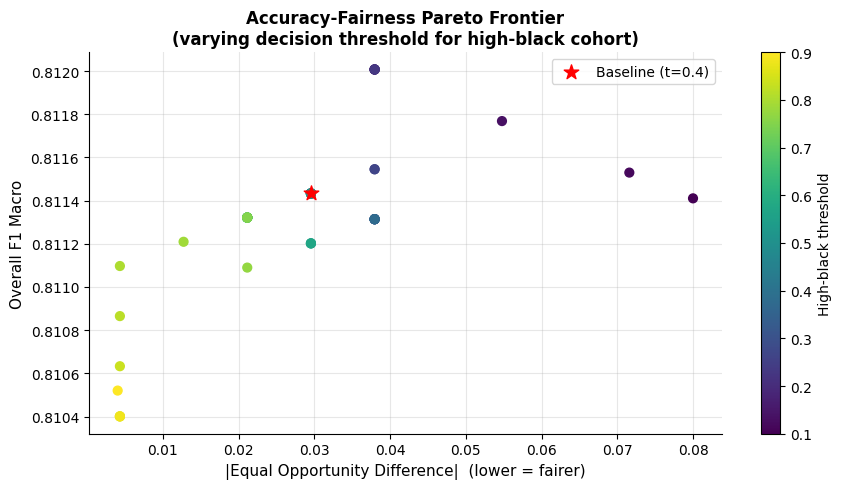

In [20]:
# ── Pareto frontier: sweep group-specific threshold for high-black cohort ─────
# Fix reference cohort threshold at CHOSEN_THRESHOLD (0.4)
# Vary high-black threshold from 0.1 to 0.9
# At each point: compute overall F1 and equal opportunity difference

sweep_thresholds = np.linspace(0.1, 0.9, 50)
pareto_f1, pareto_eod_vals = [], []

for t_black in sweep_thresholds:
    preds_sweep = df_eval["pred_label"].copy().values.astype(int)
    # Override high-black cohort predictions at threshold t_black
    preds_sweep[mask_black.values] = (toxic_probs[mask_black.values] >= t_black).astype(int)

    f1_s  = f1_score(true_labels, preds_sweep, average="macro")

    df_eval["pred_sweep"] = preds_sweep
    _, eod_s = aif360_fairness(df_eval, pred_col="pred_sweep")

    pareto_f1.append(f1_s)
    pareto_eod_vals.append(abs(eod_s))  # absolute value: distance from 0

fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(pareto_eod_vals, pareto_f1, c=sweep_thresholds, cmap="viridis", s=40, zorder=3)
plt.colorbar(sc, ax=ax, label="High-black threshold")

# Mark baseline and chosen threshold
baseline_idx = np.argmin(np.abs(sweep_thresholds - CHOSEN_THRESHOLD))
ax.scatter(pareto_eod_vals[baseline_idx], pareto_f1[baseline_idx],
           color="red", s=120, zorder=5, label=f"Baseline (t={CHOSEN_THRESHOLD})", marker="*")

ax.set_xlabel("|Equal Opportunity Difference|  (lower = fairer)", fontsize=11)
ax.set_ylabel("Overall F1 Macro", fontsize=11)
ax.set_title("Accuracy-Fairness Pareto Frontier\n(varying decision threshold for high-black cohort)",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("checkpoints/pareto_frontier.png", dpi=150)
plt.show()

# Clean up sweep column
df_eval.drop(columns=["pred_sweep"], inplace=True)

# Technique 3 — Oversampling (Data Augmentation)

Duplicate all high-black cohort training examples 3× (so each appears 4 times total). This forces the model to see more examples of the underrepresented subgroup during training, reducing the spurious correlations it learns.

In [ ]:
# ── Identify high-black rows in training set ──────────────────────────────────
train_black_mask = df_train["black"] >= 0.5
df_train_black   = df_train[train_black_mask]

print(f"High-black rows in training set : {len(df_train_black):,}")
print(f"Duplicating 3x (4x total)...")

# Concatenate original training set + 3 copies of high-black rows
df_train_os = pd.concat(
    [df_train] + [df_train_black] * 3,
    ignore_index=True
)
df_train_os = df_train_os.sample(frac=1, random_state=SEED).reset_index(drop=True)  # shuffle

print(f"Training set size after oversampling : {len(df_train_os):,}")
print(f"Label balance after oversampling:")
print(df_train_os["label"].value_counts().to_string())

In [ ]:
os_train_dataset = JigsawDataset(
    df_train_os["comment_text"].tolist(),
    df_train_os["label"].tolist(),
    tokenizer, MAX_LENGTH
)

model_os = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model_os.to(DEVICE)

trainer_os = Trainer(
    model=model_os,
    args=get_training_args("checkpoints/distilbert-oversample"),
    train_dataset=os_train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics
)

print("Training oversampled model...")
trainer_os.train()

In [ ]:
# ── Evaluate oversampled model ────────────────────────────────────────────────
probs_os = get_probs(trainer_os, eval_dataset)
preds_os = (probs_os >= CHOSEN_THRESHOLD).astype(int)

df_eval["pred_os"] = preds_os

os_f1    = f1_score(true_labels, preds_os, average="macro")
os_fpr_b = cohort_fpr(df_eval[mask_black], pred_col="pred_os")
os_fpr_r = cohort_fpr(df_eval[mask_ref],   pred_col="pred_os")
os_spd, os_eod = aif360_fairness(df_eval, pred_col="pred_os")

results_table.append({
    "Technique"       : "Oversampling (data aug)",
    "Overall F1"      : round(os_f1,    4),
    "High-black FPR"  : round(os_fpr_b, 4),
    "Reference FPR"   : round(os_fpr_r, 4),
    "Stat. Parity Δ"  : round(os_spd,   4),
    "Equal Opp. Δ"    : round(os_eod,   4),
})

np.save("checkpoints/probs_oversample.npy", probs_os)
trainer_os.save_model("checkpoints/best_model_os")
tokenizer.save_pretrained("checkpoints/best_model_os")

print(f"Oversampling results:")
print(f"  F1 Macro       : {os_f1:.4f}  (baseline: {baseline_f1:.4f})")
print(f"  High-black FPR : {os_fpr_b:.4f}  (baseline: {baseline_fpr_b:.4f})")
print(f"  Reference FPR  : {os_fpr_r:.4f}  (baseline: {baseline_fpr_r:.4f})")
print(f"  Stat. Parity Δ : {os_spd:.4f}  (baseline: {baseline_spd:.4f})")
print(f"  Equal Opp. Δ   : {os_eod:.4f}  (baseline: {baseline_eod:.4f})")

---
## Full Comparison Table

In [ ]:
df_results = pd.DataFrame(results_table)
print("=" * 85)
print("MITIGATION COMPARISON TABLE")
print("=" * 85)
print(df_results.to_string(index=False))
df_results.to_csv("checkpoints/mitigation_comparison.csv", index=False)
print("\nSaved to checkpoints/mitigation_comparison.csv")

# ── Identify best model by highest F1 with improved high-black FPR ────────────
improved = df_results[df_results["High-black FPR"] < baseline_fpr_b]
if len(improved) > 0:
    best_row = improved.loc[improved["Overall F1"].idxmax()]
    print(f"\nBest mitigated model: {best_row['Technique']}")
else:
    best_row = df_results.iloc[1]  # fallback to reweighing
    print("No technique improved both F1 and FPR — using Reweighing as best model.")

In [ ]:
# ── Visualise comparison table ────────────────────────────────────────────────
metrics_viz  = ["Overall F1", "High-black FPR", "Reference FPR", "Stat. Parity Δ", "Equal Opp. Δ"]
techniques   = df_results["Technique"].tolist()
colors       = ["#5B8DB8", "#E07B54", "#6BAE75", "#C94040"]

fig, axes = plt.subplots(1, len(metrics_viz), figsize=(18, 5))

for ax, metric in zip(axes, metrics_viz):
    vals = df_results[metric].values.astype(float)
    bars = ax.bar(range(len(techniques)), vals, color=colors, edgecolor="white")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(techniques)))
    ax.set_xticklabels([t.split(" (")[0] for t in techniques], rotation=20, ha="right", fontsize=8)
    ax.set_title(metric, fontsize=10, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Mitigation Techniques: Impact on Accuracy and Fairness Metrics",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("checkpoints/mitigation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Key Question: Can We Simultaneously Achieve Demographic Parity AND Equalized Odds?

### Short answer: No — and the math shows exactly why.

**Definitions:**
- **Demographic parity** (statistical parity): $P(\hat{Y}=1 \mid A=0) = P(\hat{Y}=1 \mid A=1)$ — same positive prediction rate across groups
- **Equalized odds**: $P(\hat{Y}=1 \mid Y=y, A=0) = P(\hat{Y}=1 \mid Y=y, A=1)$ for $y \in \{0,1\}$ — same TPR AND same FPR across groups

**The decomposition:**

The positive prediction rate can be written as:
$$P(\hat{Y}=1 \mid A=a) = \text{TPR}_a \cdot P(Y=1 \mid A=a) + \text{FPR}_a \cdot P(Y=0 \mid A=a)$$

If equalized odds holds: $\text{TPR}_0 = \text{TPR}_1 = \text{TPR}$ and $\text{FPR}_0 = \text{FPR}_1 = \text{FPR}$.

For demographic parity to also hold:
$$\text{TPR} \cdot P(Y=1 \mid A=0) + \text{FPR} \cdot P(Y=0 \mid A=0) = \text{TPR} \cdot P(Y=1 \mid A=1) + \text{FPR} \cdot P(Y=0 \mid A=1)$$

Rearranging:
$$\text{(TPR - FPR)} \cdot [P(Y=1 \mid A=0) - P(Y=1 \mid A=1)] = 0$$

This equation is zero **only if** either:
1. $\text{TPR} = \text{FPR}$ — the classifier is random (useless), or
2. $P(Y=1 \mid A=0) = P(Y=1 \mid A=1)$ — the **base rates are identical**

In [ ]:
# ── Compute base rates from the eval cohorts ──────────────────────────────────
base_rate_black = df_eval.loc[mask_black, "true_label"].mean()
base_rate_ref   = df_eval.loc[mask_ref,   "true_label"].mean()
base_rate_diff  = base_rate_black - base_rate_ref

print("=" * 55)
print("BASE RATES (toxic prevalence per cohort)")
print("=" * 55)
print(f"High-black cohort  : {base_rate_black:.4f}  ({base_rate_black:.2%})")
print(f"Reference cohort   : {base_rate_ref:.4f}  ({base_rate_ref:.2%})")
print(f"Difference         : {base_rate_diff:.4f}")
print()
print("Since the base rates differ, demographic parity and equalized odds")
print("cannot both be satisfied by a non-trivial classifier.")
print()

# ── Demonstrate the incompatibility numerically ───────────────────────────────
# Use baseline TPR/FPR and show what positive prediction rate each group
# would get under equalized odds — they will differ
from sklearn.metrics import confusion_matrix

def tpr_fpr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return tp/(tp+fn), fp/(fp+tn)

tpr_b, fpr_b = tpr_fpr(df_eval.loc[mask_black, "true_label"], df_eval.loc[mask_black, "pred_label"])
tpr_r, fpr_r = tpr_fpr(df_eval.loc[mask_ref,   "true_label"], df_eval.loc[mask_ref,   "pred_label"])

# Hypothetical: equalise TPR and FPR at the average
tpr_eq = (tpr_b + tpr_r) / 2
fpr_eq = (fpr_b + fpr_r) / 2

ppr_black_eq = tpr_eq * base_rate_black + fpr_eq * (1 - base_rate_black)
ppr_ref_eq   = tpr_eq * base_rate_ref   + fpr_eq * (1 - base_rate_ref)

print("Under equalised TPR/FPR (equalized odds satisfied):")
print(f"  Shared TPR              : {tpr_eq:.4f}")
print(f"  Shared FPR              : {fpr_eq:.4f}")
print(f"  PPR high-black cohort   : {ppr_black_eq:.4f}")
print(f"  PPR reference cohort    : {ppr_ref_eq:.4f}")
print(f"  PPR difference          : {ppr_black_eq - ppr_ref_eq:.4f}")
print()
print("=> PPR differs between groups even under equalized odds.")
print("   Demographic parity is therefore NOT simultaneously achievable.")

### Interpretation

The calculation above confirms the **impossibility theorem** (Chouldechova 2017, Kleinberg et al. 2016): when base rates differ between groups, no non-trivial classifier can simultaneously satisfy demographic parity and equalized odds.

In our case the base rates are close (both around 27%) but not identical. Even this small difference is enough to create a gap in positive prediction rates under equalized odds. The gap is small here — which is why the ThresholdOptimizer can get close to satisfying both — but it cannot close it completely without either:

1. Degrading to a near-random classifier (TPR ≈ FPR), or
2. Using a different intervention that changes the underlying score distributions (which retraining-based methods like Reweighing attempt)

**Practical implication for this platform:** the team must choose which fairness criterion to prioritise. Given the civil rights concern raised in the scenario — the model over-flags Black identity content — **FPR parity is the higher-priority target** than TPR parity. A platform that silences legitimate speech from a specific demographic group causes more harm than one that misses some toxic content uniformly.